In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [2]:
churn_data = pd.read_csv(r"D:\Ml_Projects\customer_churn_pridiction\customerChurn_dataset\Churn_Modelling.csv")

In [3]:
churn_data

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [4]:
churn_data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
churn_data.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [6]:
churn_data.describe()


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [13]:
churn_data.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


In [15]:
churn_data.shape

(10000, 14)

In [17]:
churn_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [19]:
churn_data.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [21]:
churn_data.duplicated().sum()

0

In [23]:
## Outliers Processsing 

In [25]:
exclude_features = ["RowNumber", "CustomerId", "Exited"]

numeric_features = [
    col
    for col in churn_data.select_dtypes(include=["int64", "float64"]).columns
    if col not in exclude_features
]
print(numeric_features)

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [27]:
outlier_summary =[]

for column in numeric_features:
    Q1 =  churn_data[column].quantile(0.25)
    Q3 =  churn_data[column].quantile(0.75)
    
    IQR = Q3- Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = churn_data[
        (churn_data[column] < lower_bound) |
        (churn_data[column]> upper_bound)
    ]

    outlier_count = len(outliers)
    outlier_percentage = (outlier_count / len(churn_data)) * 100
    
    outlier_summary.append({
    "feature":column,
    "outliers": outlier_count,
    "percentage":round(outlier_percentage, 2)
    })



In [29]:
outlier_summary

[{'feature': 'CreditScore', 'outliers': 15, 'percentage': 0.15},
 {'feature': 'Age', 'outliers': 359, 'percentage': 3.59},
 {'feature': 'Tenure', 'outliers': 0, 'percentage': 0.0},
 {'feature': 'Balance', 'outliers': 0, 'percentage': 0.0},
 {'feature': 'NumOfProducts', 'outliers': 60, 'percentage': 0.6},
 {'feature': 'HasCrCard', 'outliers': 0, 'percentage': 0.0},
 {'feature': 'IsActiveMember', 'outliers': 0, 'percentage': 0.0},
 {'feature': 'EstimatedSalary', 'outliers': 0, 'percentage': 0.0}]

In [31]:
outlier_df = pd.DataFrame(outlier_summary)

In [33]:
outlier_df

,feature,outliers,percentage
0,CreditScore,15,0.15
1,Age,359,3.59
2,Tenure,0,0.00
3,Balance,0,0.00
4,NumOfProducts,60,0.60
5,HasCrCard,0,0.00
6,IsActiveMember,0,0.00
7,EstimatedSalary,0,0.00


In [35]:
for column in ["CreditScore", "Age", "NumOfProducts"]:

    Q1 =  churn_data[column].quantile(0.25)
    Q3 =  churn_data[column].quantile(0.75)
    
    IQR = Q3- Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_values = churn_data.loc[
        (churn_data[column] < lower_bound) |
        (churn_data[column]> upper_bound),
         column
    ]
    print(f"\nFeature: {column}")
    print(f"Lower bound: {lower_bound}")
    print(f"Upper bound: {upper_bound}")
    print("Outlier values:")
    print(outlier_values.value_counts().sort_index())



Feature: CreditScore
Lower bound: 383.0
Upper bound: 919.0
Outlier values:
CreditScore
350    5
351    1
358    1
359    1
363    1
365    1
367    1
373    1
376    2
382    1
Name: count, dtype: int64

Feature: Age
Lower bound: 14.0
Upper bound: 62.0
Outlier values:
Age
63    40
64    37
65    18
66    35
67    37
68    19
69    22
70    18
71    27
72    21
73    13
74    18
75     9
76    11
77    10
78     5
79     4
80     3
81     4
82     1
83     1
84     2
85     1
88     1
92     2
Name: count, dtype: int64

Feature: NumOfProducts
Lower bound: -0.5
Upper bound: 3.5
Outlier values:
NumOfProducts
4    60
Name: count, dtype: int64


In [37]:
cat_exclude_features = ["Surname"]
categorical_features = [
    col
    for col in churn_data.select_dtypes(include=["object","category"]).columns
    if col not in cat_exclude_features
]

print(categorical_features)

['Geography', 'Gender']


In [39]:
for column in categorical_features:
    print(f"\n{column}")
    print(churn_data[column].value_counts())


Geography
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender
Gender
Male      5457
Female    4543
Name: count, dtype: int64


##  Target Analysis phase

In [42]:
churn_data["Exited"].head()

0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

In [44]:
target_count =churn_data["Exited"].value_counts()

In [46]:
target_count

Exited
0    7963
1    2037
Name: count, dtype: int64

In [48]:
target_percentage = churn_data["Exited"].value_counts(normalize=True) * 100

In [50]:
target_percentage

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64

In [52]:
X = churn_data.drop(["RowNumber","CustomerId", "Surname", "Exited"], axis=1)
y = churn_data["Exited"]

In [54]:
y.value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [56]:
X = pd.get_dummies(
    X,
    columns=["Geography", "Gender"],
    drop_first=True,
    dtype=int
)

In [58]:
print(X.head())
print("\nShape:", X.shape)
print("\nColumns:", X.columns.tolist())

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88                  0                0   
1               1        112542.58                  0                1   
2               0        113931.57                  0                0   
3               0         93826.63                  0                0   
4               1         79084.10                  0                1   

   Gender_Male  
0            0  
1            0  
2            0  
3            0  
4            0  

Shape: (10000, 11)

Columns: ['CreditScore'

## Numeric features analysis

In [61]:
churn_data[numeric_features].describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000


array([[<Axes: title={'center': 'CreditScore'}>,
        <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Tenure'}>],
       [<Axes: title={'center': 'Balance'}>,
        <Axes: title={'center': 'NumOfProducts'}>,
        <Axes: title={'center': 'HasCrCard'}>],
       [<Axes: title={'center': 'IsActiveMember'}>,
        <Axes: title={'center': 'EstimatedSalary'}>, <Axes: >]],
      dtype=object)

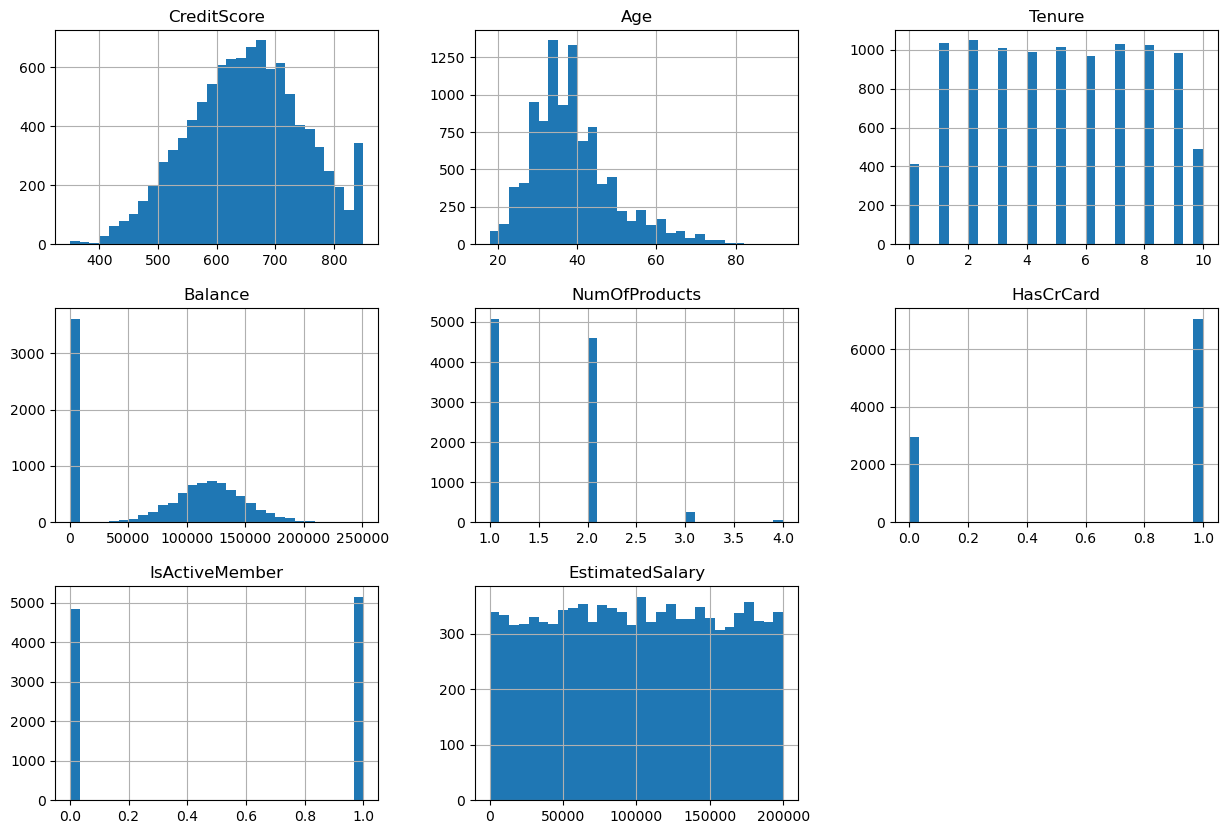

In [63]:
churn_data[numeric_features].hist(
    figsize=(15,10),
    bins=30
)

In [64]:
skewness = churn_data[numeric_features].skew()
skewness.sort_values(ascending=False)

Age                1.011320
NumOfProducts      0.745568
Tenure             0.010991
EstimatedSalary    0.002085
IsActiveMember    -0.060437
CreditScore       -0.071607
Balance           -0.141109
HasCrCard         -0.901812
dtype: float64

In [65]:
churn_data.groupby("Exited")[numeric_features].mean()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
Exited,,,,,,,,
0,651.853196,37.408389,5.033279,72745.296779,1.544267,0.707146,0.554565,99738.391772
1,645.351497,44.837997,4.932744,91108.539337,1.475209,0.699067,0.360825,101465.677531


### Compare Churn Rate (numeric)

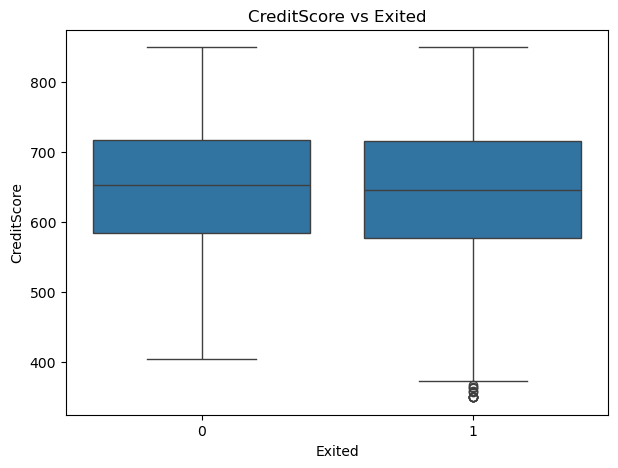

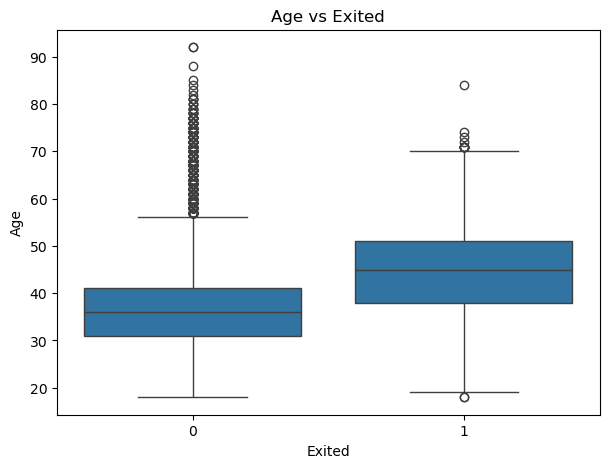

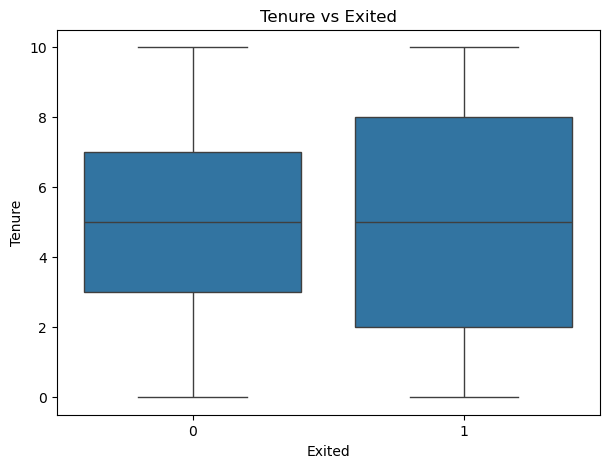

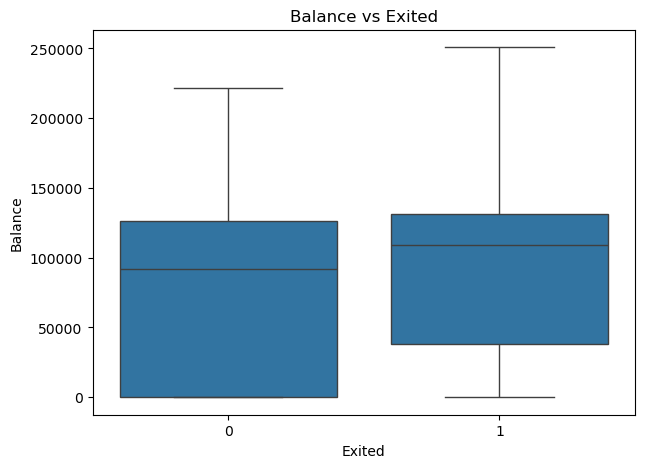

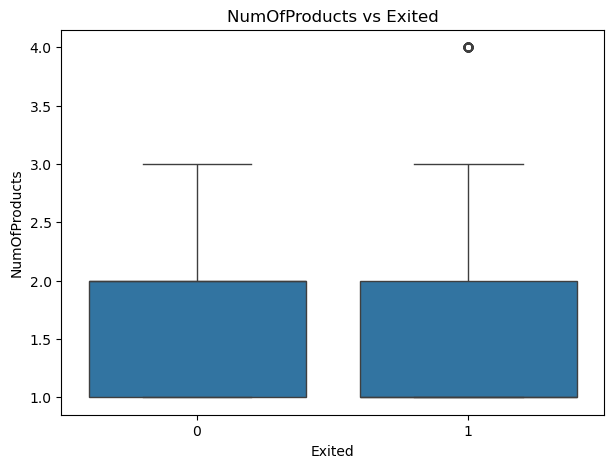

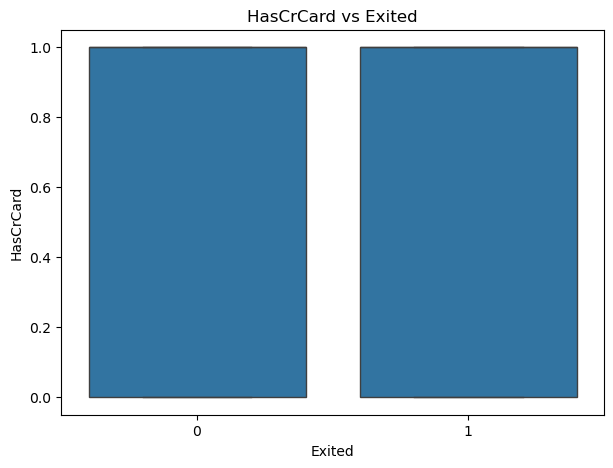

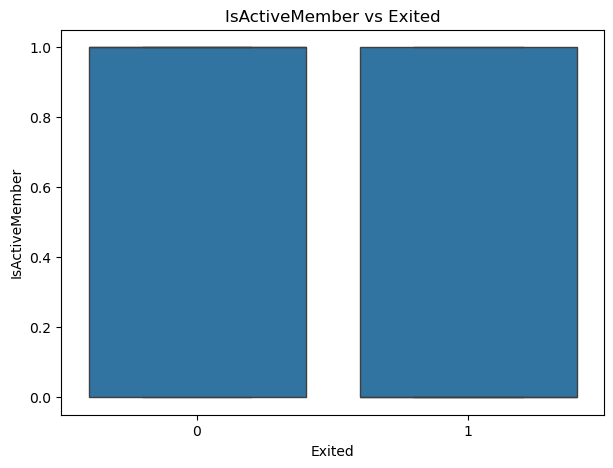

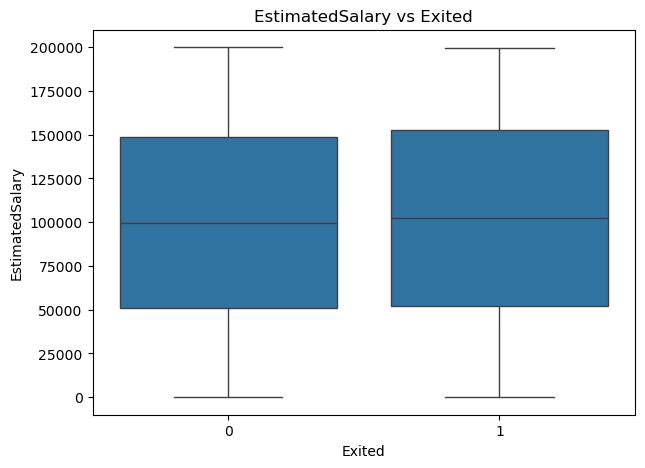

In [70]:
for column in numeric_features:
    plt.figure(figsize=(7,5))
    sns.boxplot(
    data=churn_data,
    x="Exited",
    y=column
    )
    plt.title(f"{column} vs Exited")
    plt.xlabel("Exited")
    plt.ylabel(column)
    

### Compare Churn Rate (Categorical)

In [72]:
for column in categorical_features:
    print(f"\n{column}")



Geography

Gender


In [74]:
churn_data[column].unique()

array(['Female', 'Male'], dtype=object)

In [76]:
churn_data["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [78]:
churn_data["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [80]:
pd.crosstab(
    churn_data["Geography"],
    churn_data["Exited"],
    normalize="index"
) * 100

Exited,0,1
Geography,,
France,83.845233,16.154767
Germany,67.556796,32.443204
Spain,83.326605,16.673395


<Axes: xlabel='Geography', ylabel='count'>

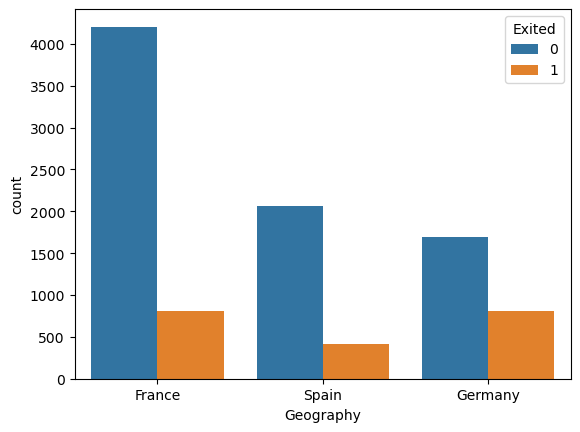

In [82]:
sns.countplot(
    data=churn_data,
    x="Geography",
    hue="Exited"
)

In [84]:
pd.crosstab(
    churn_data["Gender"],
    churn_data["Exited"],
    normalize="index"
) * 100

Exited,0,1
Gender,,
Female,74.928461,25.071539
Male,83.544072,16.455928


<Axes: xlabel='Gender', ylabel='count'>

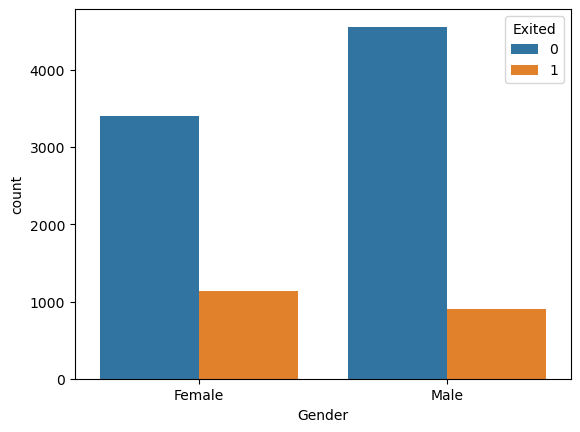

In [86]:
sns.countplot(
    data=churn_data,
    x="Gender",
    hue="Exited"
)

## Train / Validation

#### Split correctly

In [113]:
X = churn_data.drop(columns = ["RowNumber","CustomerId", "Surname", "Exited"])

y = churn_data["Exited"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (10000, 10)
Target Shape: (10000,)


In [179]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test  = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [181]:
print("X_train:", X_train.shape)
print("X_test:", X_val.shape)
print("y_train:", y_train.shape)
print("y_test:", y_val.shape)

X_train: (8000, 10)
X_test: (2000, 10)
y_train: (8000,)
y_test: (2000,)


## Preprocessing :  numeric scaling

###  categorical scaling :

In [232]:
numeric_features = [
    "CreditScore",            
    "Age",
    "Tenure",            
    "Balance",          
    "NumOfProducts",    
    "EstimatedSalary"              
]

categorical_features = [
    "Geography",
    "Gender"
]

In [535]:
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE   ## combile both dataset after processing 
from sklearn.impute import SimpleImputer   ## imputation
from sklearn.preprocessing import OneHotEncoder, StandardScaler   ## Scaling

In [537]:
### Numerical pipeline

In [539]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [541]:
### Categorical pipeline

In [543]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first",handle_unknown="ignore"))
])
    

In [545]:
###Combine both

In [558]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

### Balance Training Data and build model

In [561]:
# ## Train Logistic regression

model = Pipeline([
     ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier",LogisticRegression(max_iter=2000))
])

In [563]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier', LogisticRegression(max_iter=2000))])

In [565]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report

In [567]:
# Logistic Regression + SMOTE
y_pred_lr_smote = model.predict(X_test)
y_prob_lr_smote = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_lr_smote))
print("Precision:", precision_score(y_test, y_pred_lr_smote, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr_smote, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr_smote, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr_smote))

Accuracy: 0.7065
Precision: 0.3773841961852861
Recall: 0.6805896805896806
F1 Score: 0.4855390008764242
ROC-AUC: 0.7500921568718179


Text(0.5, 1.0, 'Confusion matrix - Logistic Regression')

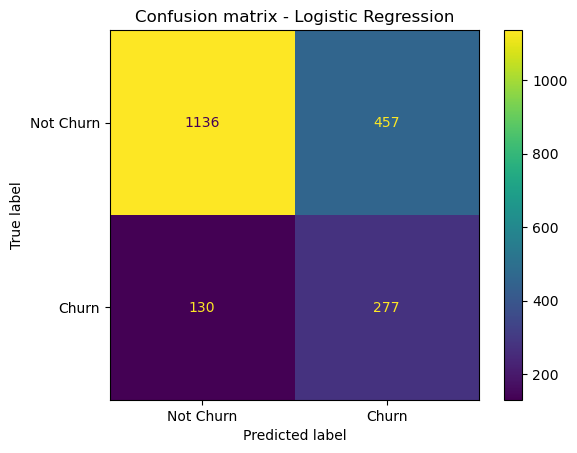

In [569]:
cm = confusion_matrix(y_test, y_pred_lr_smote)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

disp.plot()
plt.title("Confusion matrix - Logistic Regression")

### Decision Tree model 


In [436]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=5,random_state=42))
])

dt_model.fit(X_train, y_train)

y_pred_dt =  dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

print("Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report: ")
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.8485
Precision: 0.7300884955752213
Recall: 0.40540540540540543
F1 Score: 0.5213270142180095
ROC-AUC: 0.8235068658797472
Confusion Matrix: 
[[1532   61]
 [ 242  165]]

Classification Report: 
              precision    recall  f1-score   support

           0       0.86      0.96      0.91      1593
           1       0.73      0.41      0.52       407

    accuracy                           0.85      2000
   macro avg       0.80      0.68      0.72      2000
weighted avg       0.84      0.85      0.83      2000



In [438]:
dt_smote_model = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
     ("classifier", DecisionTreeClassifier(
        max_depth=6,
        random_state=42
    ))
])

In [440]:
dt_smote_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender'])])),
                ('smote', SMOTE(random_state=42)),
                ('classifier',
                 DecisionTreeClassifier(max_depth=6, random_state=42))])

In [442]:
y_pred_dt_smote = dt_smote_model.predict(X_test)
y_prob_dt_smote = dt_smote_model.predict_proba(X_test)[:,1]

In [444]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt_smote))
print("Precision:", precision_score(y_test, y_pred_dt_smote))
print("Recall:", recall_score(y_test, y_pred_dt_smote))
print("F1 Score:", f1_score(y_test, y_pred_dt_smote))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt_smote))

print("Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred_dt_smote))

print("\nClassification Report: ")
print(classification_report(y_test, y_pred_dt_smote))

Accuracy: 0.7765
Precision: 0.4695121951219512
Recall: 0.7567567567567568
F1 Score: 0.5794920037629351
ROC-AUC: 0.8303241608326354
Confusion Matrix: 
[[1245  348]
 [  99  308]]

Classification Report: 
              precision    recall  f1-score   support

           0       0.93      0.78      0.85      1593
           1       0.47      0.76      0.58       407

    accuracy                           0.78      2000
   macro avg       0.70      0.77      0.71      2000
weighted avg       0.83      0.78      0.79      2000



Text(0.5, 1.0, 'Confusion matrix - Logistic Regression')

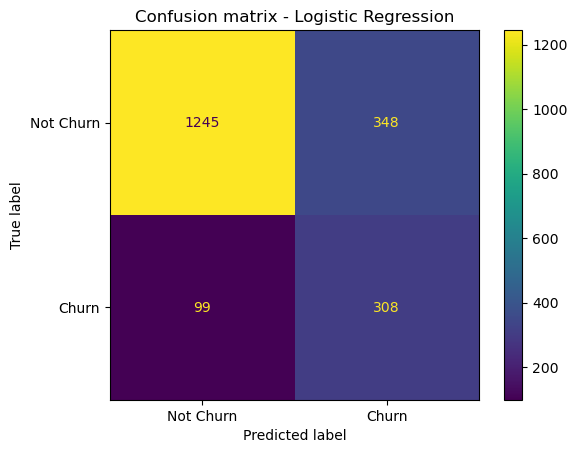

In [446]:
cm = confusion_matrix(y_test, y_pred_dt_smote)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

disp.plot()
plt.title("Confusion matrix - Logistic Regression")

In [478]:
## split trainnign data for validation set
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [489]:
results = []

# Test different hyperparameter combinations
for depth in [5, 6, 7, 9]:
    for min_split in [2, 10, 20]:
        for min_leaf in [1, 5, 10]:

            model = Pipeline([
                ("preprocessor", preprocessor),
                ("smote", SMOTE(random_state=42)),
                ("classifier", DecisionTreeClassifier(
                    max_depth=depth,
                    min_samples_split=min_split,
                    min_samples_leaf=min_leaf,
                    random_state=42
                ))
            ])

         
            model.fit(X_train_sub, y_train_sub)

            y_pred = model.predict(X_val)
            y_prob = model.predict_proba(X_val)[:, 1]

            # Evaluate the model
            results.append({
                "max_depth": depth,
                "min_samples_split": min_split,
                "min_samples_leaf": min_leaf,
                "accuracy": accuracy_score(y_val, y_pred),
                "precision": precision_score(
                    y_val, y_pred, zero_division=0
                ),
                "recall": recall_score(
                    y_val, y_pred, zero_division=0
                ),
                "f1": f1_score(
                    y_val, y_pred, zero_division=0
                ),
                "roc_auc": roc_auc_score(y_val, y_prob)
            })


# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# based on F1 score
top_results = results_df.sort_values(
    by="f1",
    ascending=False
).head(10)

print("Total combinations tested:", len(results_df))
print("\nTop 10 Hyperparameter Combinations:\n")

print(top_results.round(3).to_string(index=False))


Total combinations tested: 36

Top 10 Hyperparameter Combinations:

 max_depth  min_samples_split  min_samples_leaf  accuracy  precision  recall    f1  roc_auc
         6                  2                 1     0.772      0.464   0.773 0.580    0.834
         6                 10                 1     0.772      0.464   0.773 0.580    0.834
         7                 10                 1     0.781      0.476   0.733 0.577    0.840
         7                  2                 1     0.781      0.475   0.733 0.577    0.838
         6                 20                 1     0.769      0.461   0.770 0.576    0.832
         7                 10                 5     0.780      0.474   0.733 0.576    0.840
         7                  2                 5     0.780      0.474   0.733 0.576    0.840
         6                 20                10     0.769      0.460   0.770 0.576    0.831
         6                  2                 5     0.769      0.460   0.770 0.576    0.833
         6  

In [493]:
# combine training subset and validation data

X_train_final = pd.concat([X_train_sub, X_val])
y_train_final = pd.concat([y_train_sub, y_val])

# create selected model
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    ))
])

final_model.fit(X_train_final, y_train_final)

print("Final model trainned successfully!")

Final model trainned successfully!


In [497]:
# Decision Tree Model evaluation

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:,1]

# Calculate evaluation metrics

print("Final Model Evaluation")
print("-" * 35)

print("Accuracy :", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision :", round(precision_score(y_test, y_test_pred), 4))
print("Recall :", round(recall_score(y_test, y_test_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_test_pred), 4))
print("ROC-AUC :", round(roc_auc_score(y_test, y_test_prob), 4)

print("\nClassification Report:")
print(classification_report(y_test,y_test_pred, zero_division=0))

Final Model Evaluation
-----------------------------------
Accuracy : 0.7775
Precision : 0.4712
Recall : 0.7641
F1 Score : 0.5829
ROC-AUC : 0.8346

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.78      0.85      1593
           1       0.47      0.76      0.58       407

    accuracy                           0.78      2000
   macro avg       0.70      0.77      0.72      2000
weighted avg       0.84      0.78      0.79      2000



In [501]:
cm = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("\nTrue Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives :", TP)

Confusion Matrix:
[[1244  349]
 [  96  311]]

True Negatives : 1244
False Positives: 349
False Negatives: 96
True Positives : 311


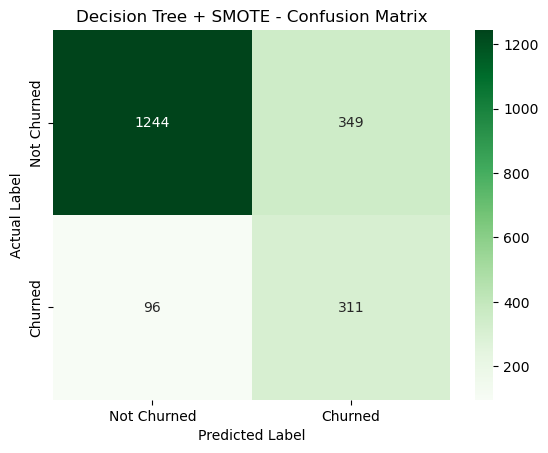

In [515]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree + SMOTE - Confusion Matrix")
plt.show()

In [571]:

models = {
    "Logistic Regression + SMOTE": (
        y_pred_lr_smote,
        y_prob_lr_smote
    ),
    "Decision Tree + SMOTE": (
        y_pred_dt_smote,
        y_prob_dt_smote
    )
}

results = {}

for model_name, (predictions, probabilities) in models.items():
    results[model_name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

           Logistic Regression + SMOTE  Decision Tree + SMOTE
Accuracy                        0.7065                 0.7765
Precision                       0.3774                 0.4695
Recall                          0.6806                 0.7568
F1 Score                        0.4855                 0.5795
ROC-AUC                         0.7501                 0.8303


In [573]:
# feature importance
# Get trained preprocessor and Decision Tree
preprocessor_fitted = final_model.named_steps["preprocessor"]
tree_model = final_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Get importance scores
importance_scores = tree_model.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort from highest to lowest
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df.head(10))

                  Feature  Importance
1                num__Age    0.476160
4      num__NumOfProducts    0.296849
3            num__Balance    0.131160
6  cat__Geography_Germany    0.055956
8        cat__Gender_Male    0.018882
2             num__Tenure    0.009813
0        num__CreditScore    0.005785
5    num__EstimatedSalary    0.005395
7    cat__Geography_Spain    0.000000


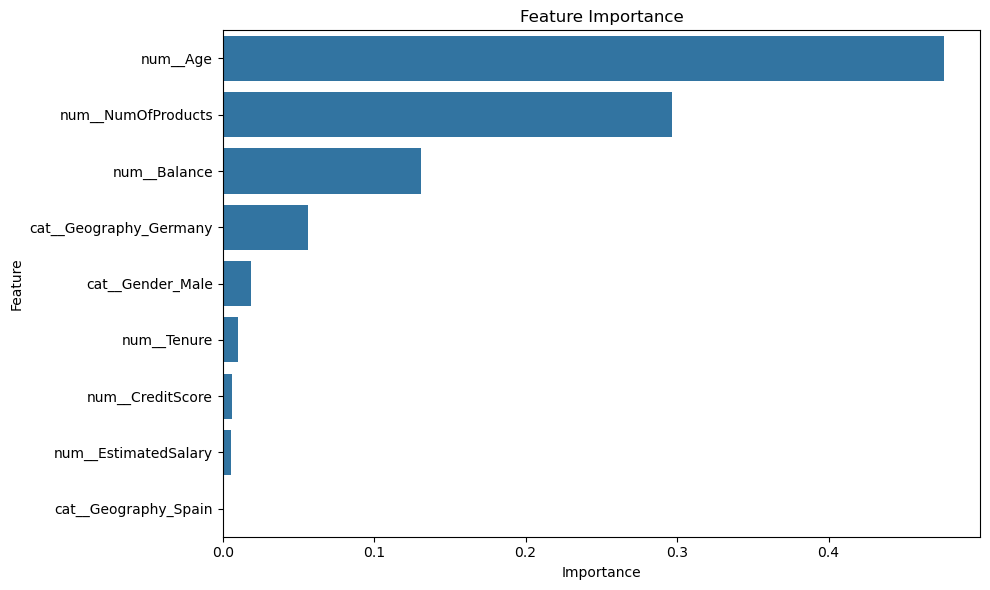

In [581]:
#Feature importance graph
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()